In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from my_helpers import plot_u_theta, plot_kh, plot_loss_history
from functools import partial
from Pwp_class import PiecewiseLinearPolynomials
from minmax_opt_class import pytree_l2_norm, MinMaxOptProb
from seq_minmax_opt_class import SequentialMinMaxOptProb


import matplotlib.pyplot as plt
import scipy.io
from scipy.interpolate import griddata

import time
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import mpmath

# Generate key which is used to generate random numbers
key = random.PRNGKey(1)

In [2]:
def u0(x):
    u = jnp.zeros_like(x)
    u = jnp.where((x > 0.0) & (x < 1.0), 1.0, u)
    return u

def u_exact(t, x):
    # Initialize u as zero
    u = 0.0
    # Condition 1: x < 0, u = 0 (already zero by default)
    # Condition 2: 0 < x < t and t > 0, u = x/t
    u = jnp.where((x > 0) & (x < t) & (t > 0), x / t, u)
    
    # Condition 3: t < x < 1 + t/2, u = 1
    u = jnp.where((x > t) & (x < 1 + t / 2), 1.0, u)
    
    # Condition 4: x > 1 + t/2, u = 0 (already zero by default)
    return u
vmap_u_exact = vmap(u_exact, in_axes=(0, 0), out_axes=0)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)


# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res_visc(u_quad, u_t, u_x, u_xx, nu):
    return u_t + u_quad * u_x - nu*u_xx
def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0
t_max = 2.5
num_segments = 5
x_min = -0.5
x_max = 2.5
Nt = 101
Nx = 401
layers = [2, 50, 50, 50, 50, 50, 1]
hidden_dims = layers[1:-1]

# Domain bounds
lb = jnp.array([t_min, x_min])
ub = jnp.array([t_max, x_max])

In [3]:
seq_trainer = SequentialMinMaxOptProb(
    num_segments=num_segments,
    total_t_min=t_min,
    total_t_max=t_max,
    seq_T = [0,1,2,2.5],
    N_t=16,
    N_x=48,
    lr_theta=0.0002,
    hidden_dims=hidden_dims,
    seed=0,
    N_bc=Nt,
    N_ic=Nx,
    x_min=x_min, x_max=x_max,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)



Plotting before training segment [0.0000, 1.0000]


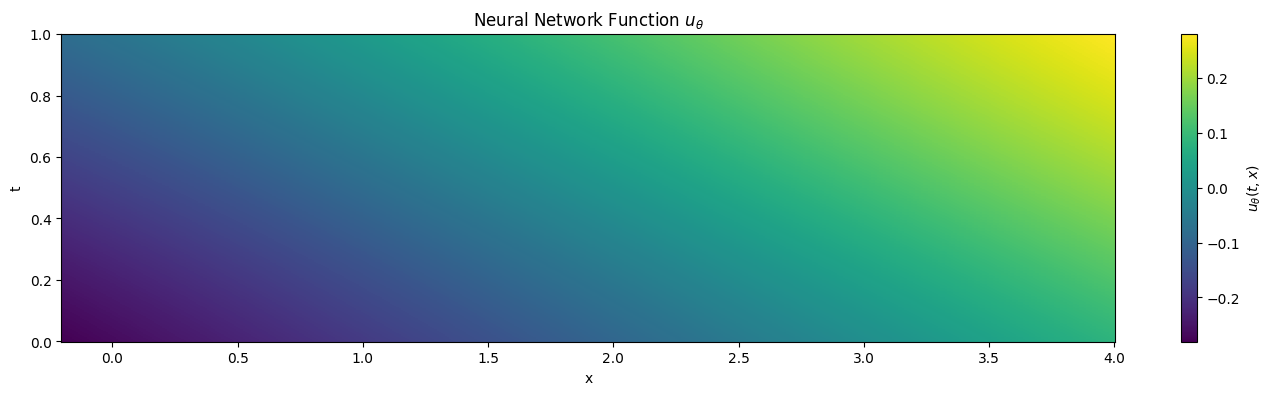


Pre-training segment [0.0000, 1.0000]

Starting Pre-Train Stage
Iteration 0, lambda_ic: 1.3478569984436035, lambda_bc: 1.3506439924240112, lambda_r: 1.0802419185638428.
Pre-train Iteration 0, Loss_int: 0.18210983, Loss_ibc: 0.44277760
Pre-train Iteration 200, Loss_int: 0.00197552, Loss_ibc: 0.20373408
Pre-train Iteration 400, Loss_int: 0.00273261, Loss_ibc: 0.19809651
Pre-train Iteration 600, Loss_int: 0.01051217, Loss_ibc: 0.14623849
Pre-train Iteration 800, Loss_int: 0.01742906, Loss_ibc: 0.04574844
Iteration 1000, lambda_ic: 1.4881963729858398, lambda_bc: 1.663309931755066, lambda_r: 1.2142428159713745.
Pre-train Iteration 1000, Loss_int: 0.00711156, Loss_ibc: 0.03136999
Pre-train Iteration 1200, Loss_int: 0.00473554, Loss_ibc: 0.02172992
Pre-train Iteration 1400, Loss_int: 0.00189265, Loss_ibc: 0.01178672
Pre-train Iteration 1600, Loss_int: 0.00142232, Loss_ibc: 0.00854653
Pre-train Iteration 1800, Loss_int: 0.00101811, Loss_ibc: 0.00731544
Iteration 2000, lambda_ic: 1.54304683208

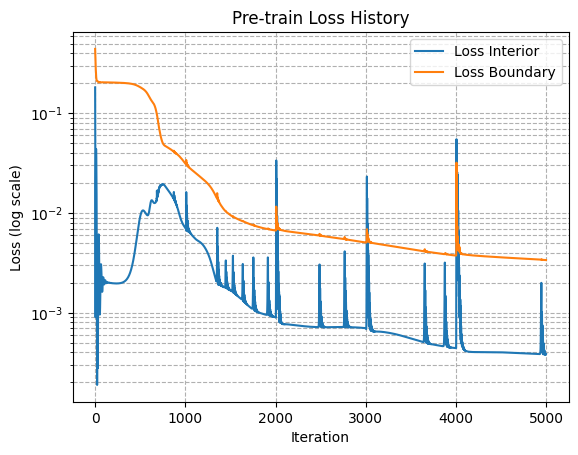


Plotting after training segment [0.0000, 1.0000]


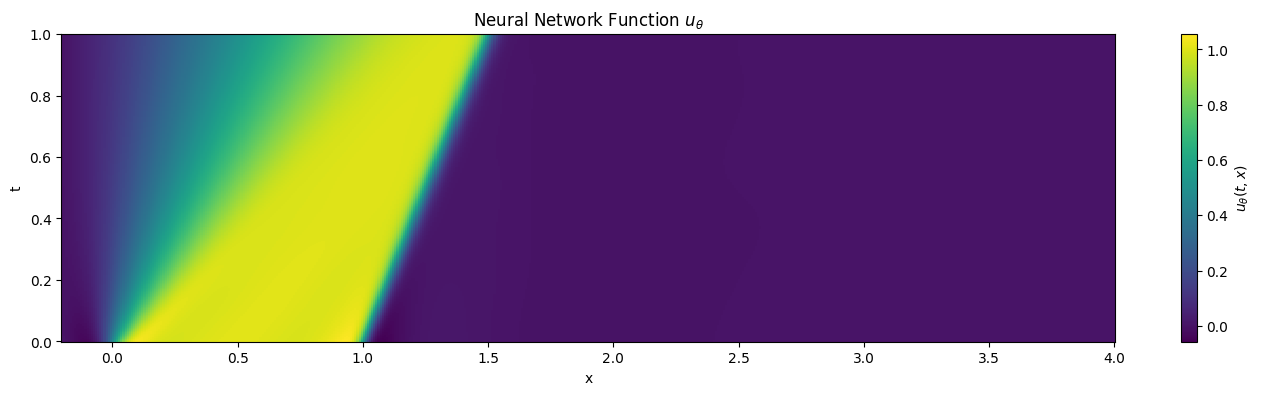


Plotting before training segment [1.0000, 2.0000]


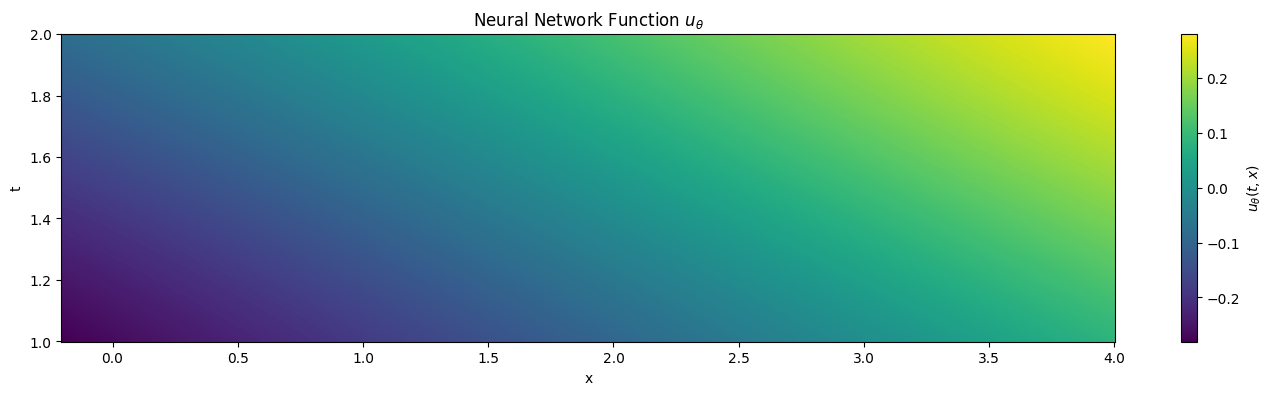


Pre-training segment [1.0000, 2.0000]

Starting Pre-Train Stage
Iteration 0, lambda_ic: 1.3870478868484497, lambda_bc: 1.340455412864685, lambda_r: 1.0761668682098389.
Pre-train Iteration 0, Loss_int: 0.18210983, Loss_ibc: 0.36950767
Pre-train Iteration 200, Loss_int: 0.00205412, Loss_ibc: 0.15313654
Pre-train Iteration 400, Loss_int: 0.00224516, Loss_ibc: 0.14702848
Pre-train Iteration 600, Loss_int: 0.01226855, Loss_ibc: 0.03033850
Pre-train Iteration 800, Loss_int: 0.00849240, Loss_ibc: 0.01750455
Iteration 1000, lambda_ic: 1.4963750839233398, lambda_bc: 1.9071478843688965, lambda_r: 1.1887564659118652.
Pre-train Iteration 1000, Loss_int: 0.00704848, Loss_ibc: 0.01561773
Pre-train Iteration 1200, Loss_int: 0.00548336, Loss_ibc: 0.01188947
Pre-train Iteration 1400, Loss_int: 0.00318437, Loss_ibc: 0.00582057
Pre-train Iteration 1600, Loss_int: 0.00101108, Loss_ibc: 0.00073307
Pre-train Iteration 1800, Loss_int: 0.00055631, Loss_ibc: 0.00030192
Iteration 2000, lambda_ic: 2.08988213539

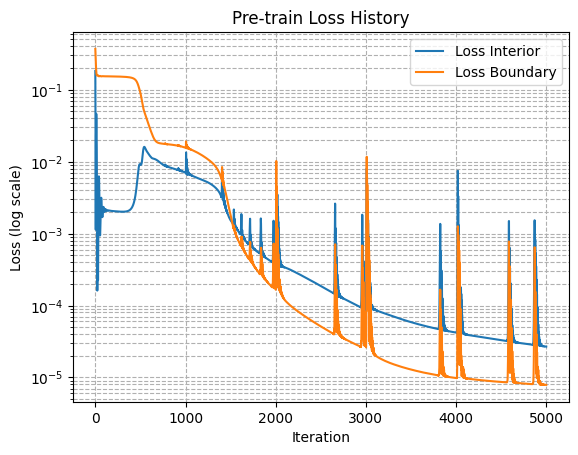


Plotting after training segment [1.0000, 2.0000]


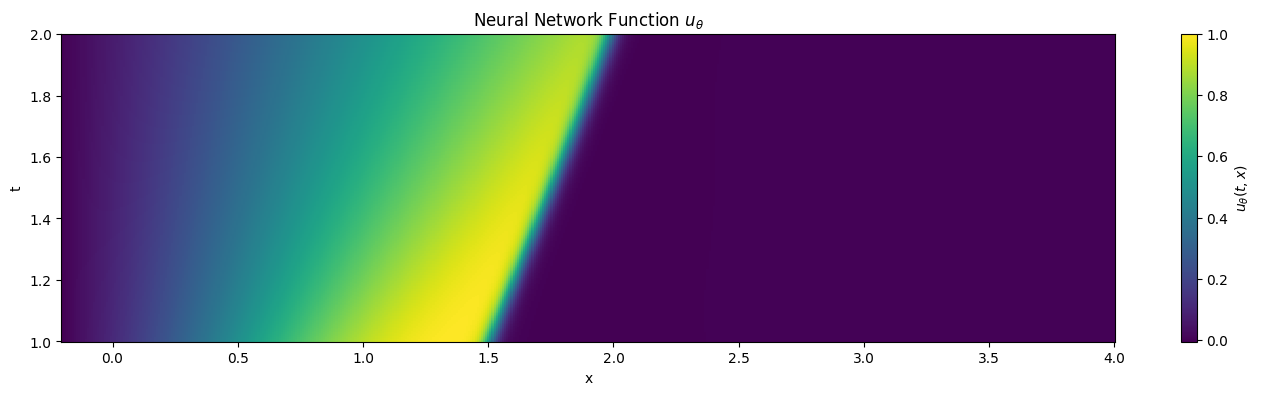


Plotting before training segment [2.0000, 2.5000]


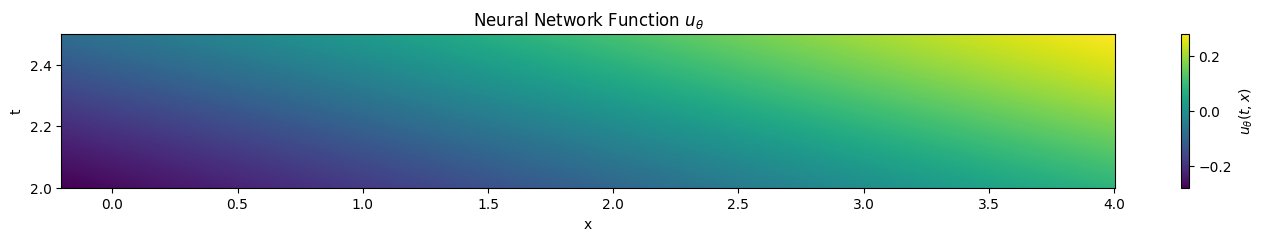


Pre-training segment [2.0000, 2.5000]

Starting Pre-Train Stage
Iteration 0, lambda_ic: 1.732682466506958, lambda_bc: 1.579909086227417, lambda_r: 1.0364576578140259.
Pre-train Iteration 0, Loss_int: 0.36349976, Loss_ibc: 0.31643751
Pre-train Iteration 200, Loss_int: 0.00182245, Loss_ibc: 0.11875217
Pre-train Iteration 400, Loss_int: 0.00184286, Loss_ibc: 0.11415229
Pre-train Iteration 600, Loss_int: 0.00944615, Loss_ibc: 0.01738847
Pre-train Iteration 800, Loss_int: 0.00516679, Loss_ibc: 0.00932068
Iteration 1000, lambda_ic: 1.8142406940460205, lambda_bc: 1.9542096853256226, lambda_r: 1.1710721254348755.
Pre-train Iteration 1000, Loss_int: 0.00375236, Loss_ibc: 0.00744768
Pre-train Iteration 1200, Loss_int: 0.00228609, Loss_ibc: 0.00479641
Pre-train Iteration 1400, Loss_int: 0.00117059, Loss_ibc: 0.00219153
Pre-train Iteration 1600, Loss_int: 0.00058898, Loss_ibc: 0.00049182
Pre-train Iteration 1800, Loss_int: 0.00045968, Loss_ibc: 0.00021585
Iteration 2000, lambda_ic: 1.990916252136

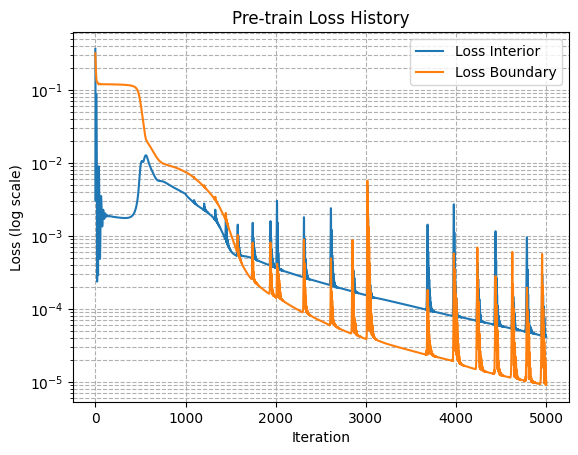


Plotting after training segment [2.0000, 2.5000]


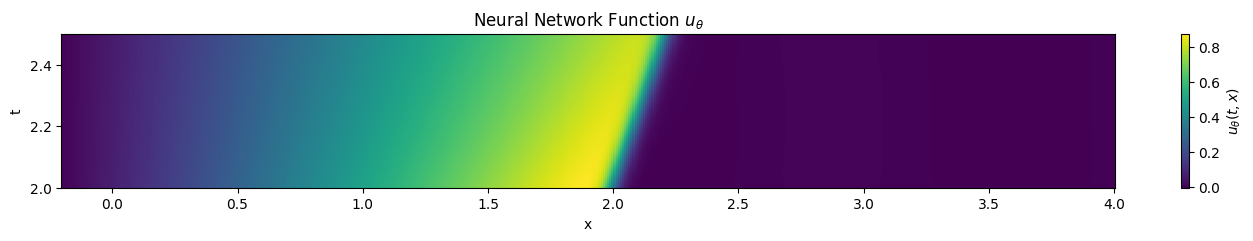


Plotting combined output across all segments from t=0 to total_t_max


TypeError: 'float' object cannot be interpreted as an integer

In [4]:
seq_trainer.train_sequential(train_num_iterations=0, pre_train_num_iterations=10000)

In [ ]:
plot_combined_u_theta(seq_trainer)


Plotting before training segment [0.0000, 0.5000]


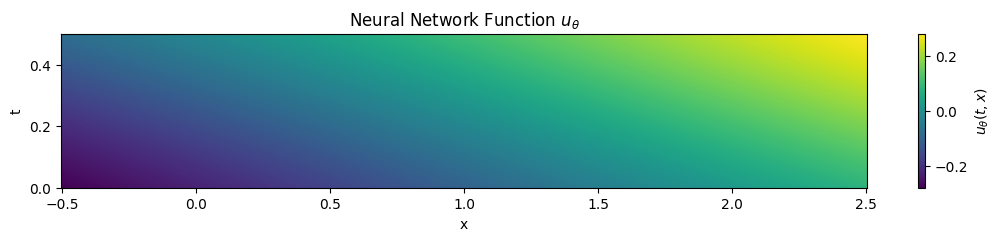


Training segment [0.0000, 0.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.59217739, lambda_bc: 9.63037777, lambda_r: 1.04869962.
Iteration 0, before maximize k_h, loss: 0.62186188, 0.54475141.
Iteration 0, after maximize k_h, loss: 0.62186188, 0.54475141.
Train Iteration 0, Loss_int: 0.62186188, Loss_bc: 0.54475141
Iteration 100, before maximize k_h, loss: 0.01542389, 0.29036495.
Iteration 100, after maximize k_h, loss: 0.01542727, 0.29036495.
Train Iteration 100, Loss_int: 0.01542728, Loss_bc: 0.29036495
Iteration 200, before maximize k_h, loss: 0.01223483, 0.28863746.
Iteration 200, after maximize k_h, loss: 0.01239368, 0.28863746.
Train Iteration 200, Loss_int: 0.01239367, Loss_bc: 0.28863749
Iteration 300, before maximize k_h, loss: 0.01983374, 0.28195453.
Iteration 300, after maximize k_h, loss: 0.01984089, 0.28195453.
Train Iteration 300, Loss_int: 0.01984090, Loss_bc: 0.28195453
Iteration 400, before maximize k_h, loss: 0.26920423, 0.06197352.
Iteration 400, after maxim

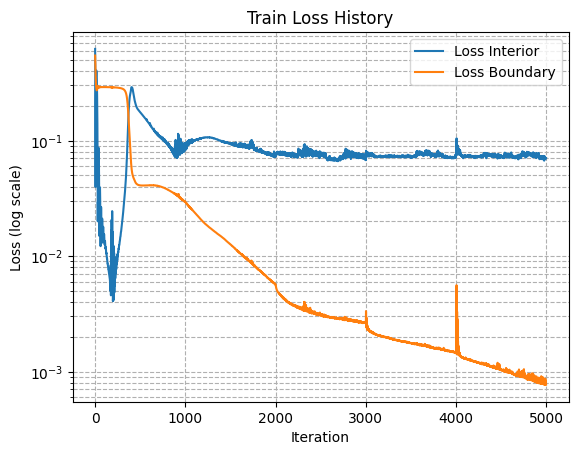


Plotting after training segment [0.0000, 0.5000]


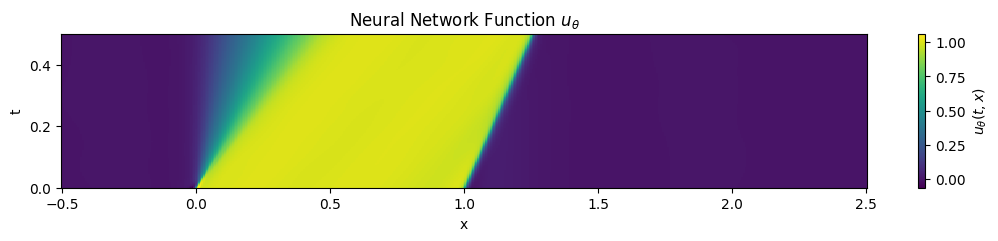


Plotting before training segment [0.5000, 1.0000]


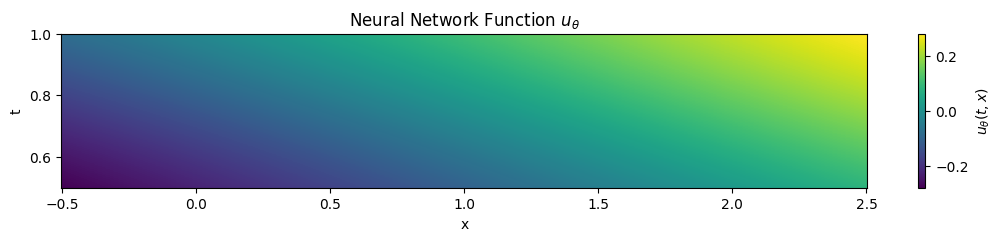


Training segment [0.5000, 1.0000]

Starting Train Stage
Iteration 0, lambda_ic: 9.65275860, lambda_bc: 9.61871147, lambda_r: 1.04594755.
Iteration 0, before maximize k_h, loss: 0.62186188, 0.49512050.
Iteration 0, after maximize k_h, loss: 0.62186188, 0.49512050.
Train Iteration 0, Loss_int: 0.62186188, Loss_bc: 0.49512053
Iteration 100, before maximize k_h, loss: 0.01611066, 0.26355985.
Iteration 100, after maximize k_h, loss: 0.01611210, 0.26355985.
Train Iteration 100, Loss_int: 0.01611209, Loss_bc: 0.26355985
Iteration 200, before maximize k_h, loss: 0.00825308, 0.26232168.
Iteration 200, after maximize k_h, loss: 0.00825327, 0.26232168.
Train Iteration 200, Loss_int: 0.00825326, Loss_bc: 0.26232168
Iteration 300, before maximize k_h, loss: 0.03224318, 0.25144321.
Iteration 300, after maximize k_h, loss: 0.03224423, 0.25144321.
Train Iteration 300, Loss_int: 0.03224428, Loss_bc: 0.25144318
Iteration 400, before maximize k_h, loss: 0.20761712, 0.02368573.
Iteration 400, after maxim

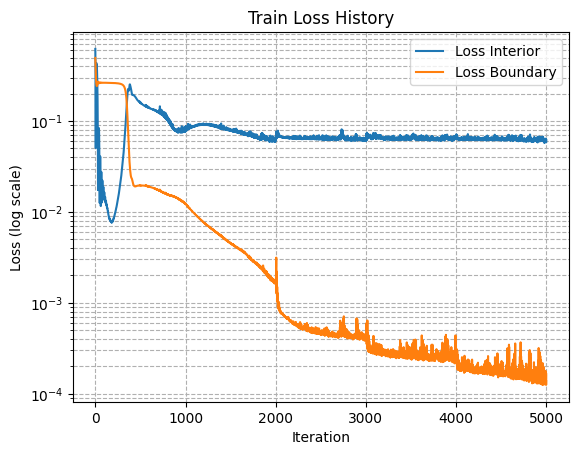


Plotting after training segment [0.5000, 1.0000]


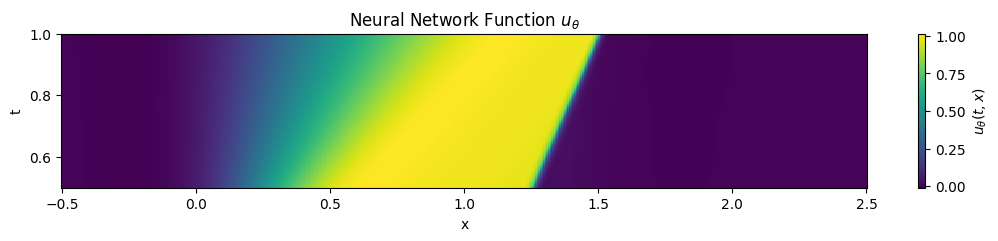


Plotting before training segment [1.0000, 1.5000]


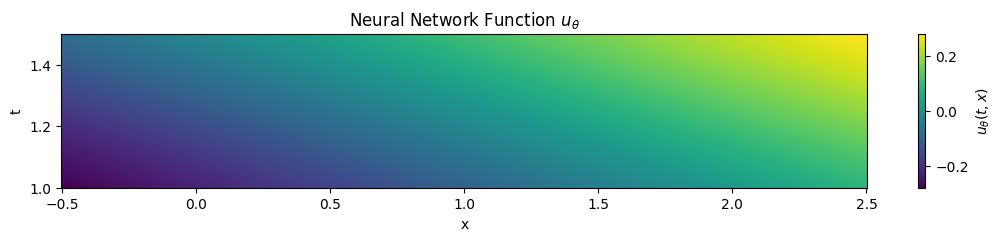


Training segment [1.0000, 1.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.72462749, lambda_bc: 9.60780525, lambda_r: 1.04337502.
Iteration 0, before maximize k_h, loss: 0.62186188, 0.44917804.
Iteration 0, after maximize k_h, loss: 0.62186188, 0.44917804.
Train Iteration 0, Loss_int: 0.62186188, Loss_bc: 0.44917807
Iteration 100, before maximize k_h, loss: 0.01387043, 0.23753443.
Iteration 100, after maximize k_h, loss: 0.01388996, 0.23753443.
Train Iteration 100, Loss_int: 0.01388980, Loss_bc: 0.23753443
Iteration 200, before maximize k_h, loss: 0.00982716, 0.23614277.
Iteration 200, after maximize k_h, loss: 0.00982817, 0.23614277.
Train Iteration 200, Loss_int: 0.00982816, Loss_bc: 0.23614280
Iteration 300, before maximize k_h, loss: 0.04020729, 0.22469461.
Iteration 300, after maximize k_h, loss: 0.04021265, 0.22469461.
Train Iteration 300, Loss_int: 0.04021267, Loss_bc: 0.22469462
Iteration 400, before maximize k_h, loss: 0.17351218, 0.02086257.
Iteration 400, after maxim

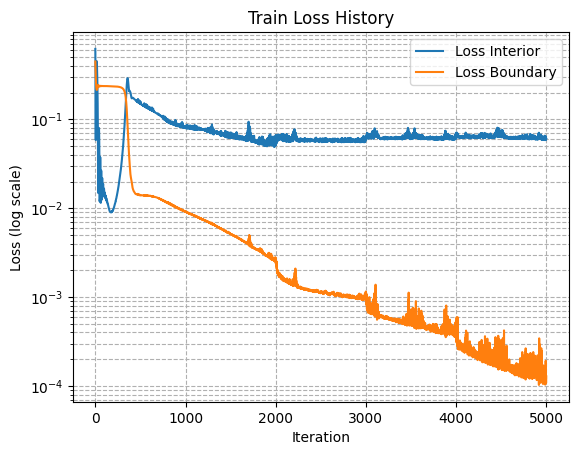


Plotting after training segment [1.0000, 1.5000]


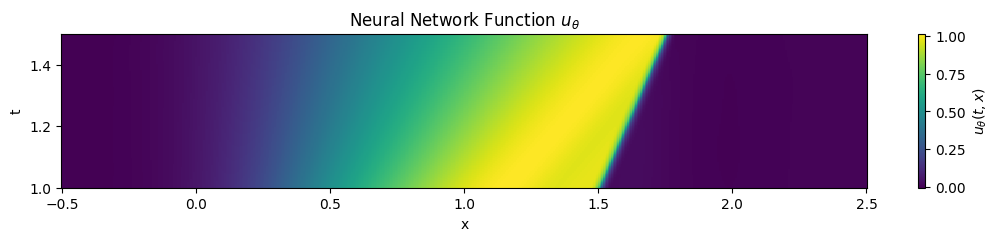


Plotting before training segment [1.5000, 2.0000]


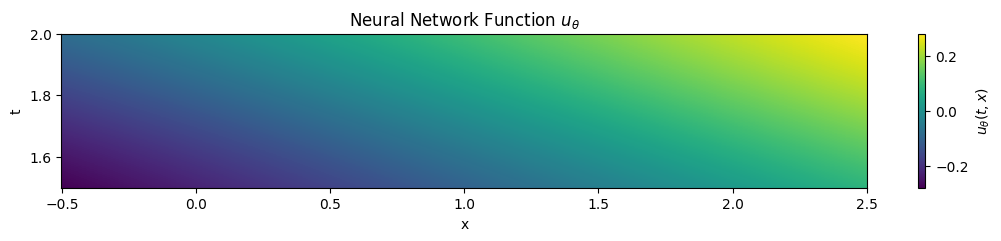


Training segment [1.5000, 2.0000]

Starting Train Stage
Iteration 0, lambda_ic: 9.80851173, lambda_bc: 9.59787464, lambda_r: 1.04103243.
Iteration 0, before maximize k_h, loss: 0.62186188, 0.40295690.
Iteration 0, after maximize k_h, loss: 0.62186188, 0.40295690.
Train Iteration 0, Loss_int: 0.62186188, Loss_bc: 0.40295693
Iteration 100, before maximize k_h, loss: 0.01372610, 0.20772503.
Iteration 100, after maximize k_h, loss: 0.01375661, 0.20772503.
Train Iteration 100, Loss_int: 0.01375660, Loss_bc: 0.20772503
Iteration 200, before maximize k_h, loss: 0.00911497, 0.20668915.
Iteration 200, after maximize k_h, loss: 0.00911634, 0.20668915.
Train Iteration 200, Loss_int: 0.00911636, Loss_bc: 0.20668918
Iteration 300, before maximize k_h, loss: 0.03496584, 0.19744298.
Iteration 300, after maximize k_h, loss: 0.03496800, 0.19744298.
Train Iteration 300, Loss_int: 0.03496800, Loss_bc: 0.19744296
Iteration 400, before maximize k_h, loss: 0.17965066, 0.03337798.
Iteration 400, after maxim

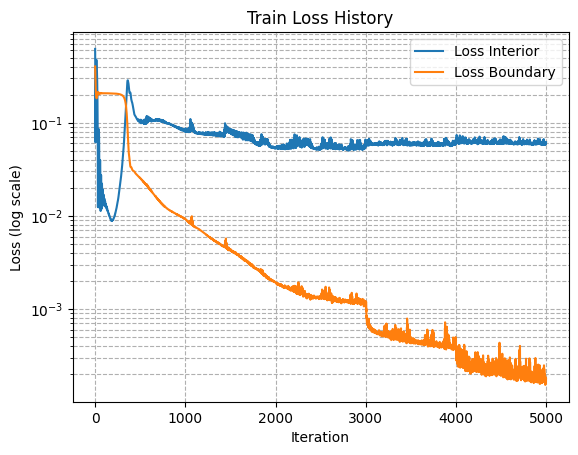


Plotting after training segment [1.5000, 2.0000]


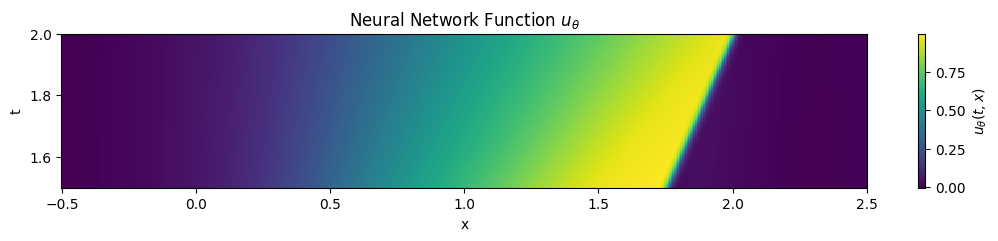


Plotting before training segment [2.0000, 2.5000]


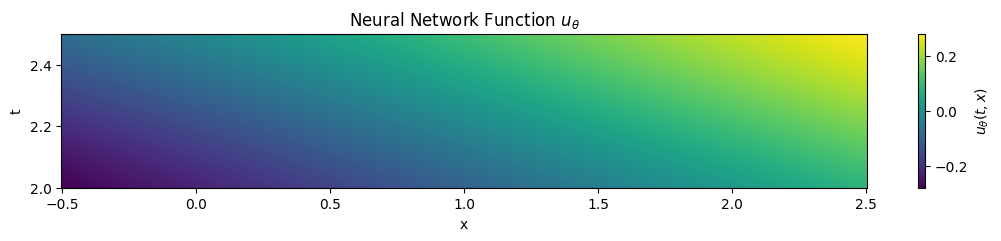


Training segment [2.0000, 2.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.89463139, lambda_bc: 9.58985996, lambda_r: 1.03914189.
Iteration 0, before maximize k_h, loss: 0.62186188, 0.36000386.
Iteration 0, after maximize k_h, loss: 0.62186188, 0.36000386.
Train Iteration 0, Loss_int: 0.62186188, Loss_bc: 0.36000386
Iteration 100, before maximize k_h, loss: 0.01280910, 0.17704368.
Iteration 100, after maximize k_h, loss: 0.01284758, 0.17704368.
Train Iteration 100, Loss_int: 0.01284759, Loss_bc: 0.17704369
Iteration 200, before maximize k_h, loss: 0.00879427, 0.17613353.
Iteration 200, after maximize k_h, loss: 0.00879429, 0.17613353.
Train Iteration 200, Loss_int: 0.00879430, Loss_bc: 0.17613353
Iteration 300, before maximize k_h, loss: 0.02724999, 0.16853106.
Iteration 300, after maximize k_h, loss: 0.02725537, 0.16853106.
Train Iteration 300, Loss_int: 0.02725537, Loss_bc: 0.16853106
Iteration 400, before maximize k_h, loss: 0.18173182, 0.03931507.
Iteration 400, after maxim

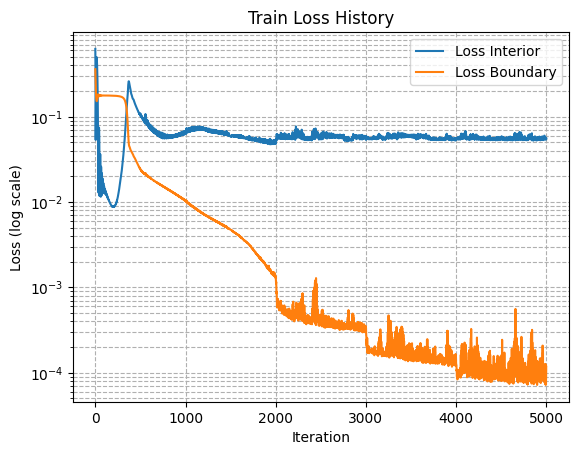


Plotting after training segment [2.0000, 2.5000]


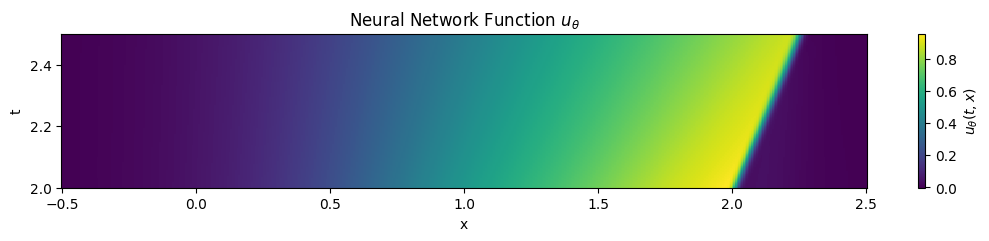


Plotting combined output across all segments from t=0 to total_t_max


TypeError: digitize requires ndarray or scalar arguments, got <class 'list'> at position 1.

In [5]:
seq_trainer_us = SequentialMinMaxOptProb(
    num_segments=num_segments,
    total_t_min=t_min,
    total_t_max=t_max,
    seq_T = [0, 0.5, 1, 1.5, 2, 2.5],
    N_t=16,
    N_x=48,
    lr_theta=0.0002,
    hidden_dims=hidden_dims,
    seed=0,
    N_bc=Nt,
    N_ic=Nx,
    x_min=x_min, x_max=x_max,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)

seq_trainer_us.train_sequential(train_num_iterations=5000, pre_train_num_iterations=0)

In [ ]:
plot_combined_u_theta(seq_trainer)

In [7]:
seq_trainer_us.segments[0].pwp.N_x


48

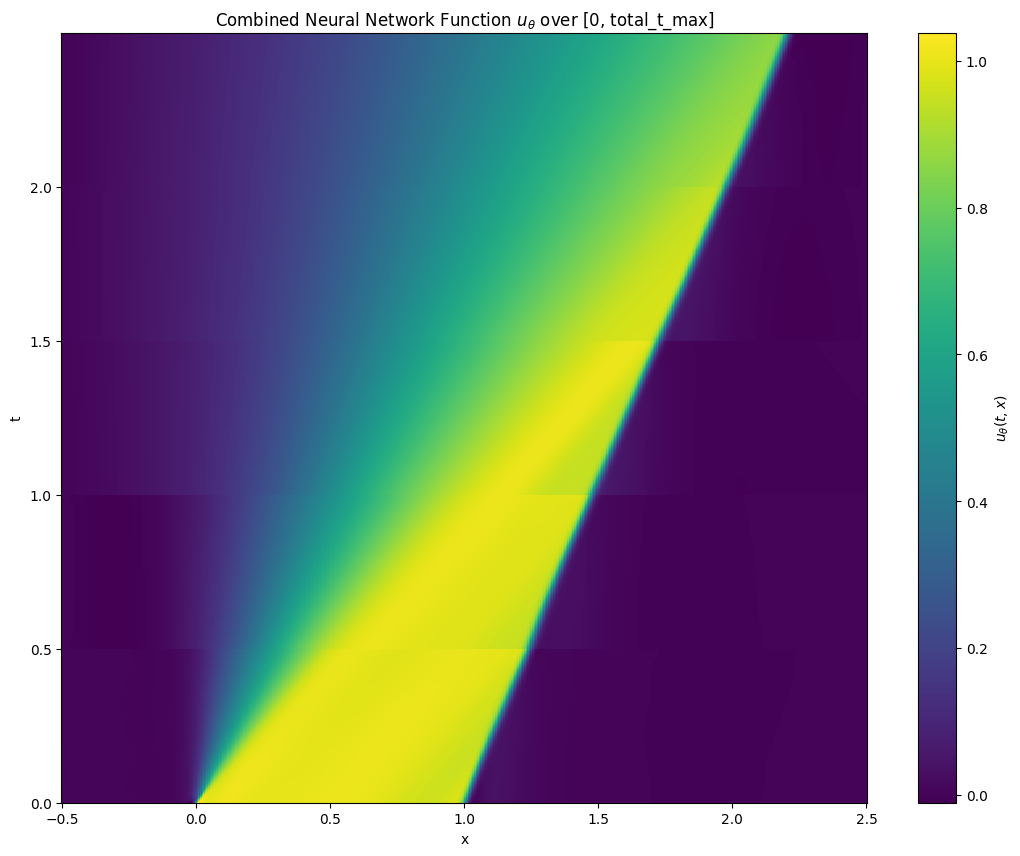

In [4]:
seq_trainer_us.seq_T = jnp.array(seq_trainer_us.seq_T)
seq_trainer_us.plot_combined_u_theta(500, M_x=500)


Plotting before training segment [0.0000, 0.5000]


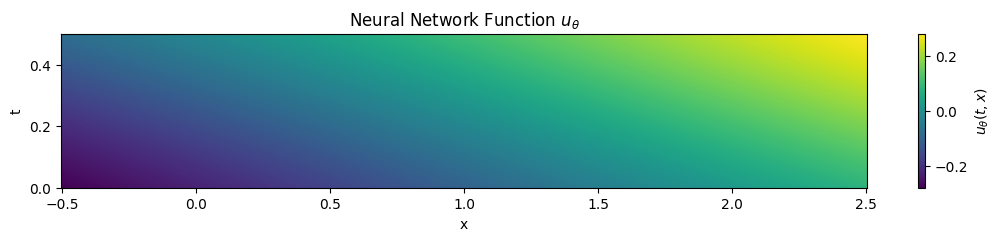


Training segment [0.0000, 0.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.61706734, lambda_bc: 9.65687370, lambda_r: 1.04583490.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.54475141.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.54475141.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.54475141
Iteration 100, before maximize k_h, loss: 0.01295575, 0.29071876.
Iteration 100, after maximize k_h, loss: 0.01297089, 0.29071876.
Train Iteration 100, Loss_int: 0.01297089, Loss_bc: 0.29071876
Iteration 200, before maximize k_h, loss: 0.00414747, 0.28954667.
Iteration 200, after maximize k_h, loss: 0.00415279, 0.28954667.
Train Iteration 200, Loss_int: 0.00415279, Loss_bc: 0.28954670
Iteration 300, before maximize k_h, loss: 0.01673362, 0.28316101.
Iteration 300, after maximize k_h, loss: 0.01673897, 0.28316101.
Train Iteration 300, Loss_int: 0.01673895, Loss_bc: 0.28316104
Iteration 400, before maximize k_h, loss: 0.25472134, 0.07439857.
Iteration 400, after maxim

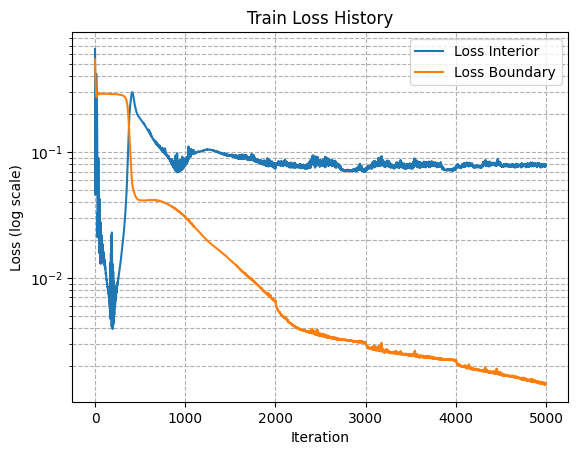


Plotting after training segment [0.0000, 0.5000]


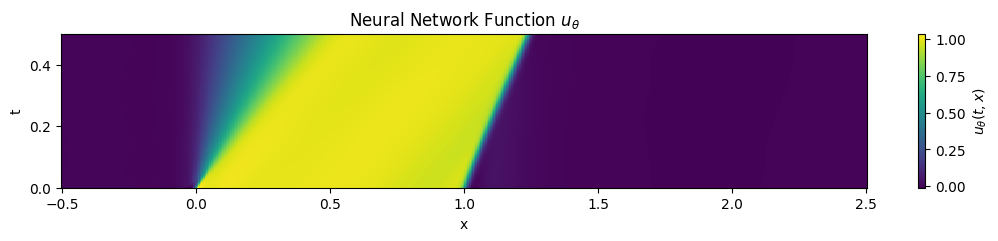


Plotting before training segment [0.5000, 1.0000]


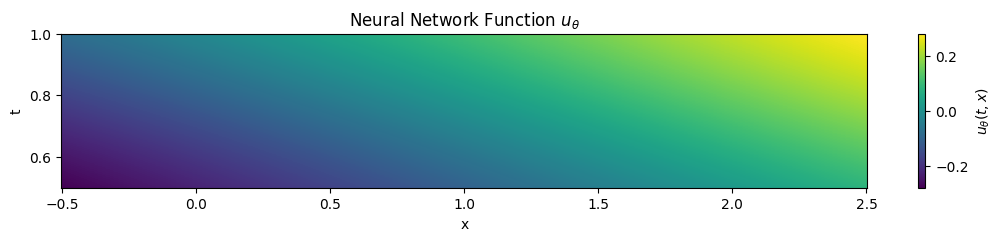


Training segment [0.5000, 1.0000]

Starting Train Stage
Iteration 0, lambda_ic: 9.68347740, lambda_bc: 9.64475727, lambda_r: 1.04314494.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.48679814.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.48679814.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.48679814
Iteration 100, before maximize k_h, loss: 0.01283348, 0.25740069.
Iteration 100, after maximize k_h, loss: 0.01284542, 0.25740069.
Train Iteration 100, Loss_int: 0.01284540, Loss_bc: 0.25740069
Iteration 200, before maximize k_h, loss: 0.00683831, 0.25603926.
Iteration 200, after maximize k_h, loss: 0.00683869, 0.25603926.
Train Iteration 200, Loss_int: 0.00683869, Loss_bc: 0.25603926
Iteration 300, before maximize k_h, loss: 0.02230417, 0.24870570.
Iteration 300, after maximize k_h, loss: 0.02230478, 0.24870570.
Train Iteration 300, Loss_int: 0.02230477, Loss_bc: 0.24870569
Iteration 400, before maximize k_h, loss: 0.24641462, 0.02775783.
Iteration 400, after maxim

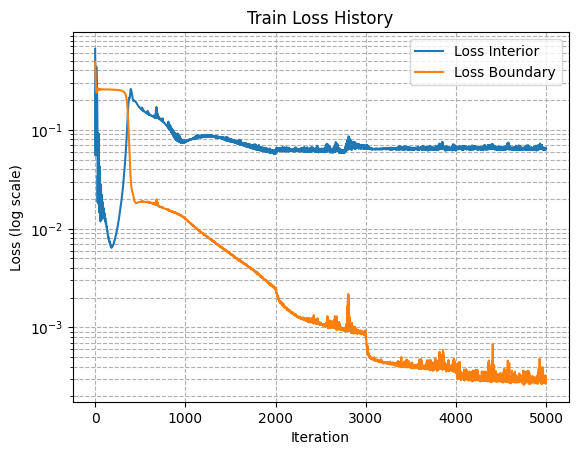


Plotting after training segment [0.5000, 1.0000]


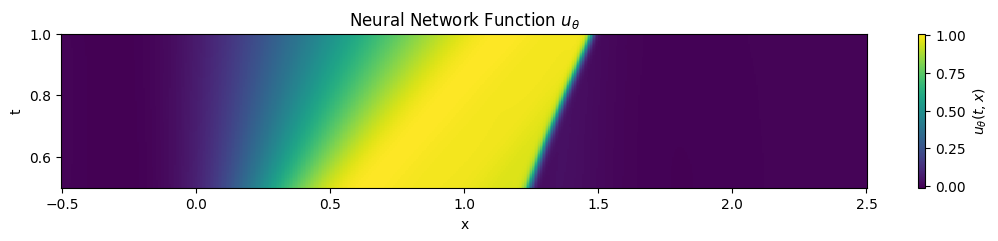


Plotting before training segment [1.0000, 1.5000]


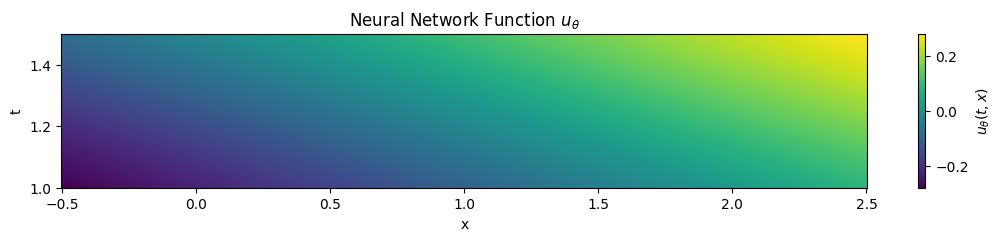


Training segment [1.0000, 1.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.75932217, lambda_bc: 9.63390541, lambda_r: 1.04073572.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.43724042.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.43724042.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.43724042
Iteration 100, before maximize k_h, loss: 0.01324273, 0.22783431.
Iteration 100, after maximize k_h, loss: 0.01325957, 0.22783431.
Train Iteration 100, Loss_int: 0.01325957, Loss_bc: 0.22783430
Iteration 200, before maximize k_h, loss: 0.00777471, 0.22671519.
Iteration 200, after maximize k_h, loss: 0.00777512, 0.22671519.
Train Iteration 200, Loss_int: 0.00777510, Loss_bc: 0.22671518
Iteration 300, before maximize k_h, loss: 0.02463662, 0.22005740.
Iteration 300, after maximize k_h, loss: 0.02463872, 0.22005740.
Train Iteration 300, Loss_int: 0.02463872, Loss_bc: 0.22005740
Iteration 400, before maximize k_h, loss: 0.20634174, 0.02794043.
Iteration 400, after maxim

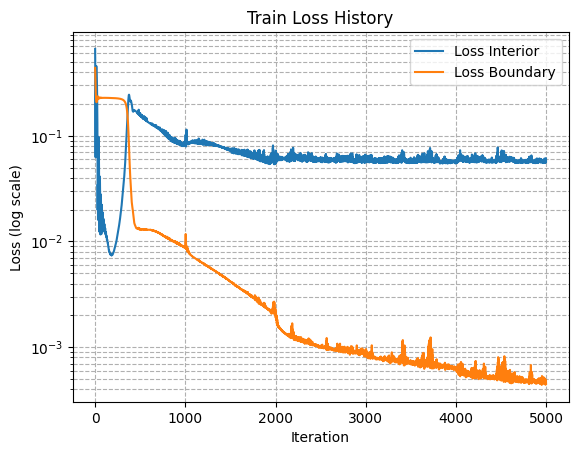


Plotting after training segment [1.0000, 1.5000]


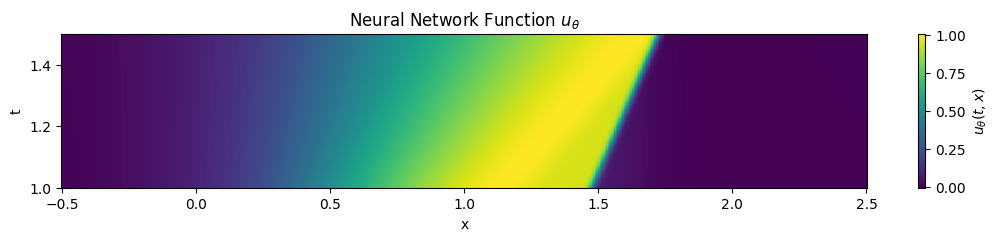


Plotting before training segment [1.5000, 2.0000]


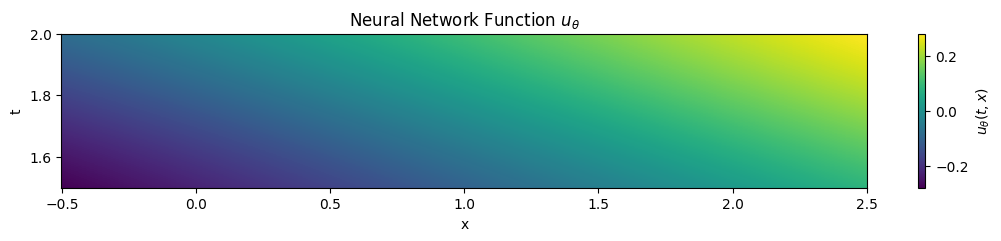


Training segment [1.5000, 2.0000]

Starting Train Stage
Iteration 0, lambda_ic: 9.82329464, lambda_bc: 9.62652206, lambda_r: 1.03909647.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.39885771.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.39885771.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.39885774
Iteration 100, before maximize k_h, loss: 0.01505068, 0.20046917.
Iteration 100, after maximize k_h, loss: 0.01507994, 0.20046917.
Train Iteration 100, Loss_int: 0.01507994, Loss_bc: 0.20046917
Iteration 200, before maximize k_h, loss: 0.00755957, 0.19981237.
Iteration 200, after maximize k_h, loss: 0.00756113, 0.19981237.
Train Iteration 200, Loss_int: 0.00756114, Loss_bc: 0.19981237
Iteration 300, before maximize k_h, loss: 0.02135558, 0.19440842.
Iteration 300, after maximize k_h, loss: 0.02135607, 0.19440842.
Train Iteration 300, Loss_int: 0.02135604, Loss_bc: 0.19440842
Iteration 400, before maximize k_h, loss: 0.20587540, 0.03825666.
Iteration 400, after maxim

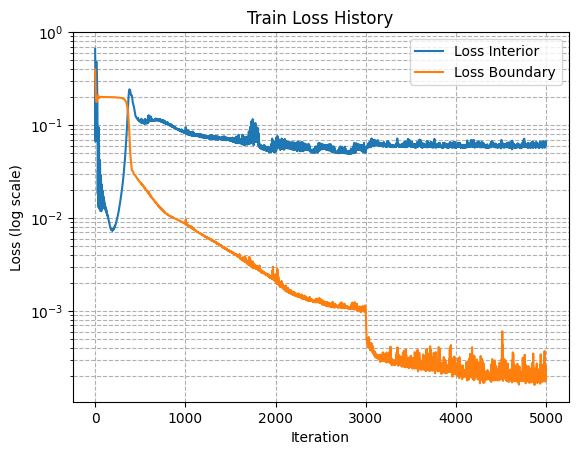


Plotting after training segment [1.5000, 2.0000]


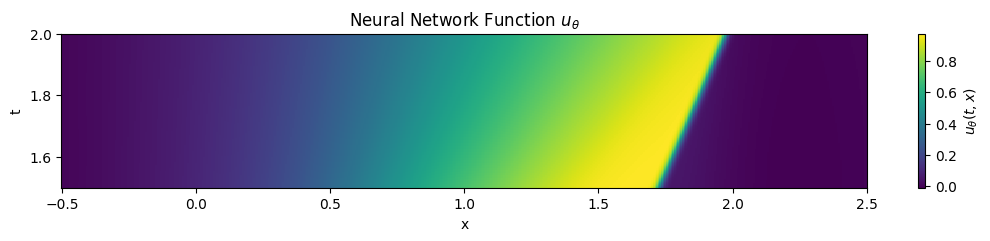


Plotting before training segment [2.0000, 2.5000]


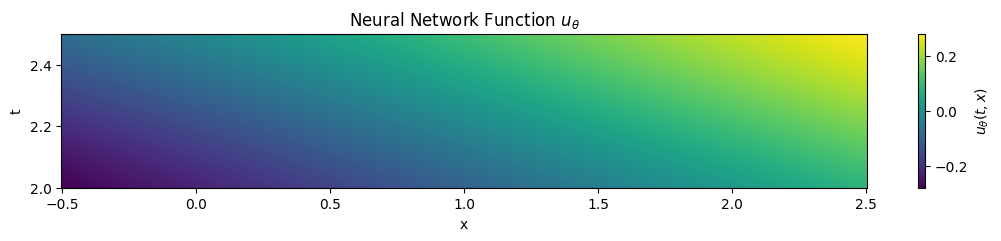


Training segment [2.0000, 2.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.90134621, lambda_bc: 9.61911011, lambda_r: 1.03745091.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.35991016.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.35991016.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.35991016
Iteration 100, before maximize k_h, loss: 0.01329953, 0.17263356.
Iteration 100, after maximize k_h, loss: 0.01337214, 0.17263356.
Train Iteration 100, Loss_int: 0.01337214, Loss_bc: 0.17263359
Iteration 200, before maximize k_h, loss: 0.00695677, 0.17204615.
Iteration 200, after maximize k_h, loss: 0.00695655, 0.17204615.
Train Iteration 200, Loss_int: 0.00695656, Loss_bc: 0.17204615
Iteration 300, before maximize k_h, loss: 0.01726374, 0.16744646.
Iteration 300, after maximize k_h, loss: 0.01726759, 0.16744646.
Train Iteration 300, Loss_int: 0.01726757, Loss_bc: 0.16744648
Iteration 400, before maximize k_h, loss: 0.21943109, 0.04249166.
Iteration 400, after maxim

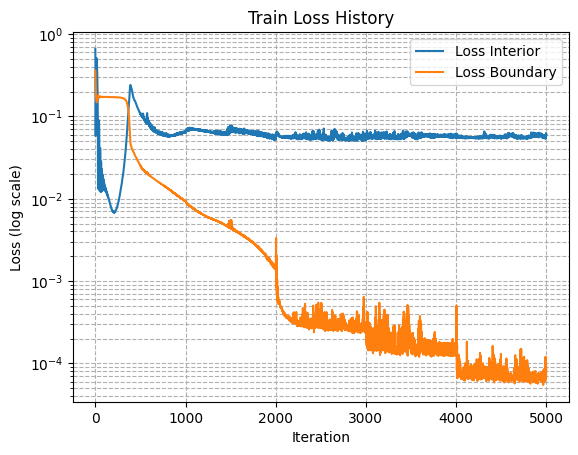


Plotting after training segment [2.0000, 2.5000]


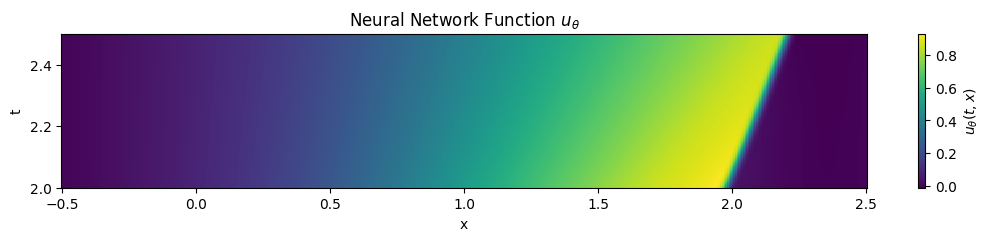


Plotting combined output across all segments from t=0 to total_t_max


TypeError: digitize requires ndarray or scalar arguments, got <class 'list'> at position 1.

In [3]:
seq_trainer_us = SequentialMinMaxOptProb(
    num_segments=num_segments,
    total_t_min=t_min,
    total_t_max=t_max,
    seq_T = [0, 0.5, 1, 1.5, 2, 2.5],
    N_t=16,
    N_x=48,
    lr_theta=0.0002,
    hidden_dims=hidden_dims,
    seed=0,
    N_bc=Nt,
    N_ic=Nx,
    x_min=x_min, x_max=x_max,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)

seq_trainer_us.train_sequential(train_num_iterations=5000, pre_train_num_iterations=0)

In [ ]:
seq_trainer_us = SequentialMinMaxOptProb(
    num_segments=num_segments,
    total_t_min=t_min,
    total_t_max=t_max,
    seq_T = np.linspace(0, 2.5, 26),
    N_t=16,
    N_x=48,
    lr_theta=0.0002,
    hidden_dims=hidden_dims,
    seed=0,
    N_bc=Nt,
    N_ic=Nx,
    x_min=x_min, x_max=x_max,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)

seq_trainer_us.train_sequential(train_num_iterations=2000, pre_train_num_iterations=0)

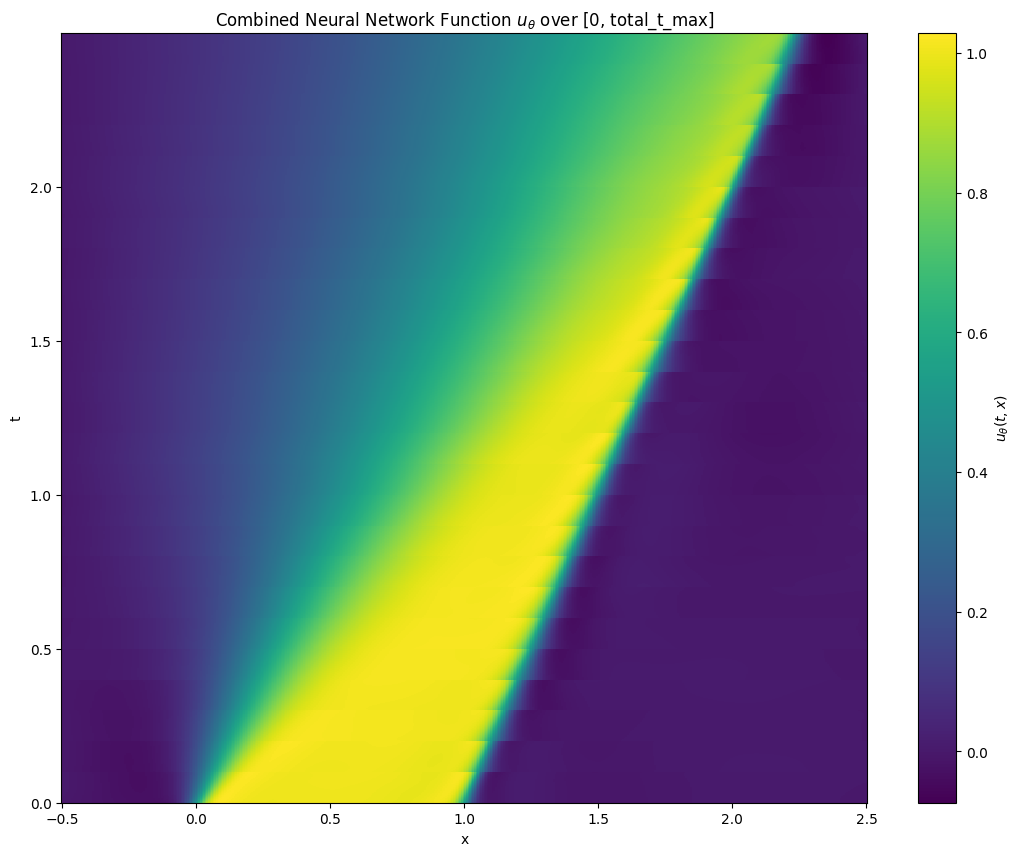

In [4]:
seq_trainer_us.plot_combined_u_theta(500, M_x=500)

In [5]:
def plot_solution_at_time(self, T, M_x=100):
    """
    Plot the solution u_theta at a specific time T.

    Args:
        T (float): The time at which to plot the solution.
        M_x (int): Number of grid points in the x-direction (default: 100).
    """
    # Find the segment that contains time T
    segment_index = None
    for i in range(len(self.seq_T) - 1):
        if self.seq_T[i] <= T < self.seq_T[i + 1]:
            segment_index = i
            break
    if segment_index is None:
        if T == self.seq_T[-1]:  # Allow T to be exactly at the end
            segment_index = len(self.seq_T) - 2
        else:
            raise ValueError(f"Time T={T} is outside the defined segments [{self.seq_T[0]}, {self.seq_T[-1]}]")

    # Get the segment
    segment = self.segments[segment_index]

    # Generate spatial grid and input points
    x_grid = jnp.linspace(self.x_min, self.x_max, M_x)
    t_fixed = jnp.full_like(x_grid, T)  # Array of T repeated for each x
    tx_points = jnp.stack([t_fixed, x_grid], axis=1)  # Shape: (M_x, 2)

    # Evaluate the neural network at these points
    u_values = segment.model(segment.params, tx_points)  # Shape: (M_x,)

    # Plot the solution
    plt.figure(figsize=(8, 6))
    plt.plot(x_grid, u_values, label=f'u_theta at t={T}')
    plt.xlabel('x')
    plt.ylabel('u_theta(T, x)')
    plt.title(f'Solution at Time T={T}')
    plt.legend()
    plt.show()

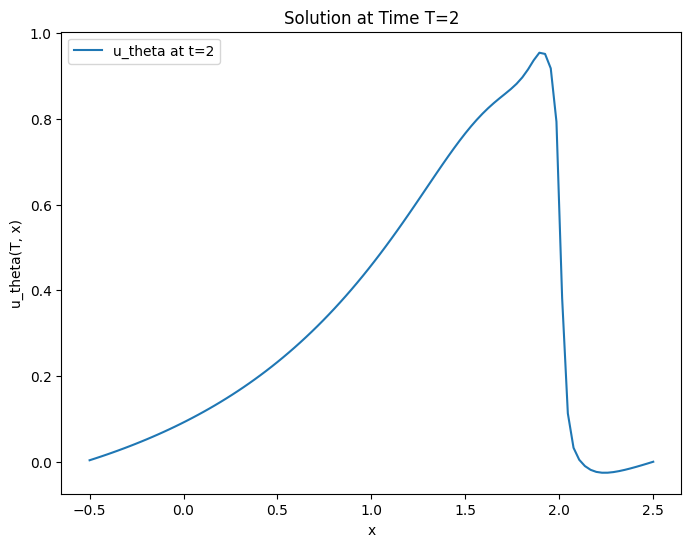

In [6]:
plot_solution_at_time(seq_trainer_us, 2)